In [7]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path    
from scipy.fft import fft, ifft
from scipy.optimize import brentq

from HATS_functions import gcc_phat, corr_to_itd, itd_to_angle, woodworth_itd, fft_cross_correlation

angles = ["-90", "-67.5", "-45", "-22.5", "0", "22.5", "45", "67.5", "90"]
heights = ["H1", "H2", "H3"]  
PathToFiles = "../Audio_Files/HATS/"

recordings = {}

for height in heights:
    recordings[height] = {}
    for angle in angles:
        folder = Path(PathToFiles) / str(height) / str(angle)
        
        if folder.is_dir():
            recordings[height][angle] = {
                'L': folder / "L.wav",
                'R': folder / "R.wav"
            }
        else:
            print(f"Missing folder: {folder}")
    
d = 0.21
c = 343
r = 0.0875 


results_gcc = {}
results_xcorr = {}

for height, angle_dict in recordings.items():
    results_gcc[height] = {}
    results_xcorr[height] = {}
    for angle, files in angle_dict.items():
        dataL, fs = sf.read(files['L'])
        dataR, fs = sf.read(files['R'])
    
        L_click_idx = np.argmax(np.abs(dataL))
        R_click_idx = np.argmax(np.abs(dataR))
    
        click_offset = R_click_idx - L_click_idx 

        L_Trimmed = dataL[L_click_idx + int(fs*2):]
        R_Trimmed = dataR[R_click_idx + int(fs*2):]

        min_len = min(len(L_Trimmed), len(R_Trimmed))
        L_Trimmed = L_Trimmed[:min_len]
        R_Trimmed = R_Trimmed[:min_len]


        correlation = gcc_phat(L_Trimmed, R_Trimmed)
        itd_seconds1 = corr_to_itd(correlation, d, fs)
        angle_deg1 = itd_to_angle(itd_seconds1, r, fs)
        itd_expected1 = woodworth_itd(float(angle), r)
        results_gcc[height][angle] = {'expected': angle, 'calculated': angle_deg1}  
        
        correlation2 = fft_cross_correlation(L_Trimmed, R_Trimmed)
        itd_seconds2 = corr_to_itd(correlation2, d, fs)
        angle_deg2 = itd_to_angle(itd_seconds2, r, fs)
        itd_expected2= woodworth_itd(float(angle), r)
        results_xcorr[height][angle] = {'expected': angle, 'calculated': angle_deg2} 


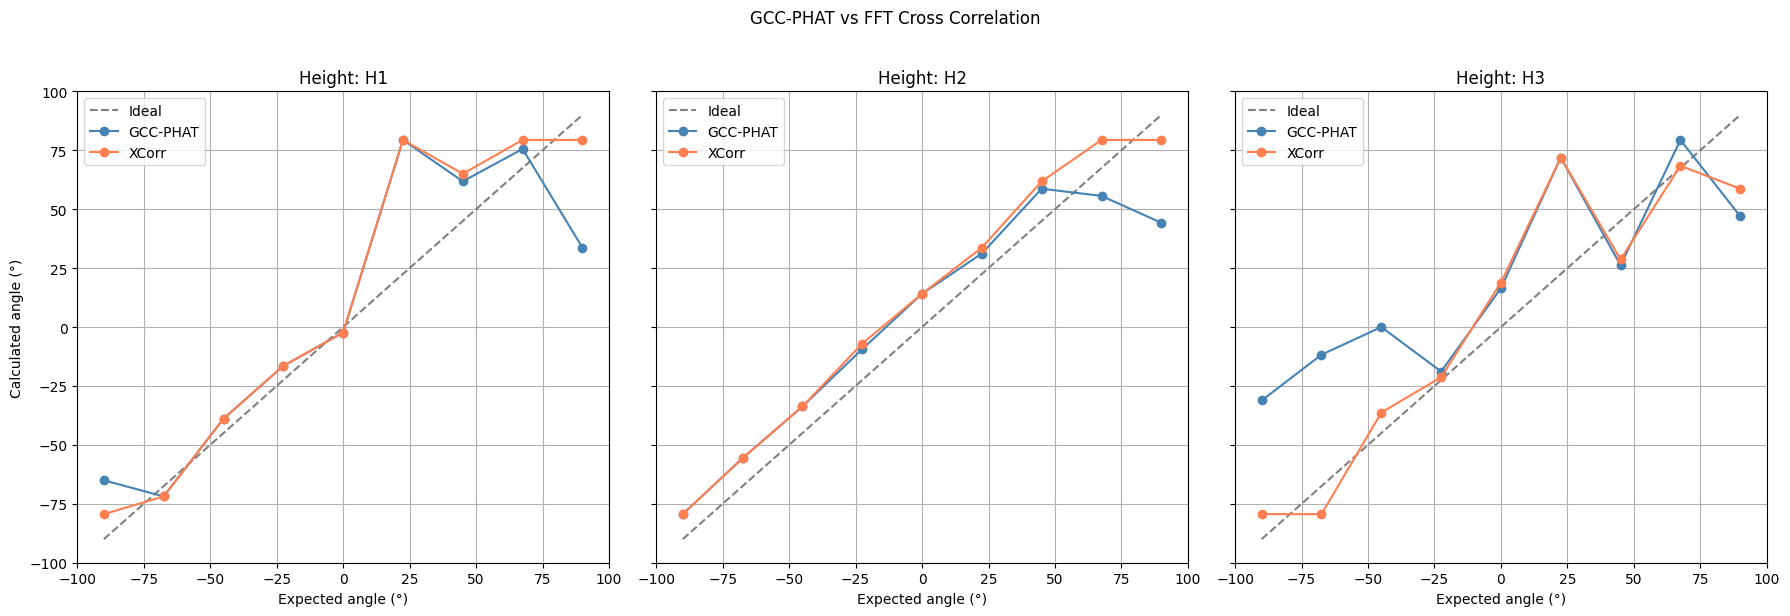

In [8]:
fig, axes = plt.subplots(1, len(results_gcc), figsize=(6*len(results_gcc), 6), sharey=True)

if len(results_gcc) == 1:
    axes = [axes]

for ax, height in zip(axes, results_gcc.keys()):
    sorted_angles = sorted(results_gcc[height].keys(), key=lambda x: float(x))
    expected = [float(a) for a in sorted_angles]
    
    gcc_calculated = [results_gcc[height][a]['calculated'] for a in sorted_angles]
    xcorr_calculated = [results_xcorr[height][a]['calculated'] for a in sorted_angles]
    
    ax.plot(expected, expected, '--', color='gray', label='Ideal')
    ax.plot(expected, gcc_calculated, 'o-', color='steelblue', label='GCC-PHAT')
    ax.plot(expected, xcorr_calculated, 'o-', color='coral', label='XCorr')
    
    ax.set_xlabel('Expected angle (°)')
    ax.set_title(f'Height: {height}')
    ax.set_xlim(-100, 100)
    ax.set_ylim(-100, 100)
    ax.grid(True)
    ax.legend()

axes[0].set_ylabel('Calculated angle (°)')
plt.suptitle('GCC-PHAT vs FFT Cross Correlation', y=1.02)
plt.tight_layout()
plt.show()

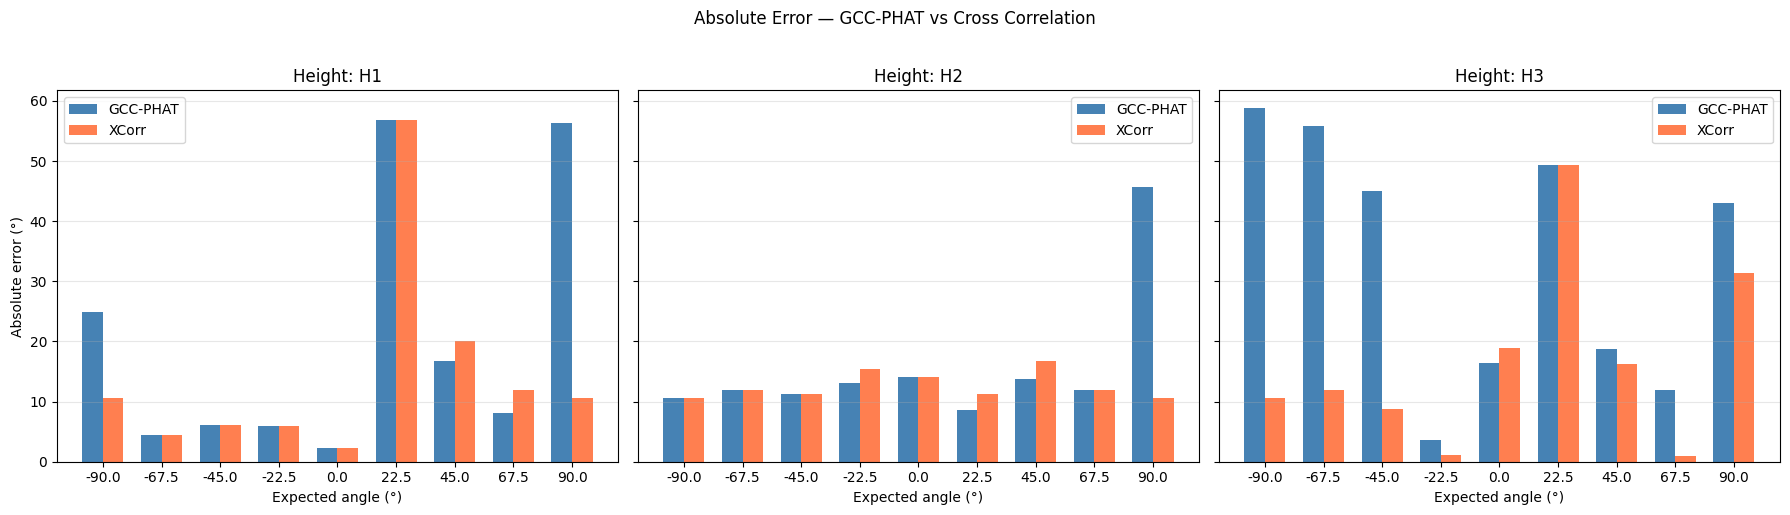

In [9]:
fig, axes = plt.subplots(1, len(results_gcc), figsize=(6*len(results_gcc), 5), sharey=True)

if len(results_gcc) == 1:
    axes = [axes]

for ax, height in zip(axes, results_gcc.keys()):
    sorted_angles = sorted(results_gcc[height].keys(), key=lambda x: float(x))
    expected = [float(a) for a in sorted_angles]
    
    gcc_error = [abs(results_gcc[height][a]['calculated'] - float(a)) for a in sorted_angles]
    xcorr_error = [abs(results_xcorr[height][a]['calculated'] - float(a)) for a in sorted_angles]
    
    x = np.arange(len(expected))
    width = 0.35
    
    ax.bar(x - width/2, gcc_error, width, color='steelblue', label='GCC-PHAT')
    ax.bar(x + width/2, xcorr_error, width, color='coral', label='XCorr')
    
    ax.set_xlabel('Expected angle (°)')
    ax.set_title(f'Height: {height}')
    ax.set_xticks(x)
    ax.set_xticklabels(expected)
    ax.grid(True, axis='y', alpha=0.3)
    ax.legend()

axes[0].set_ylabel('Absolute error (°)')
plt.suptitle('Absolute Error — GCC-PHAT vs Cross Correlation', y=1.02)
plt.tight_layout()
plt.show()